# 멀티모달 RAG — K-스틸법과 포항지역 철강산업의 전환과제 (한국은행 포항본부, 2026.9)

PDF 속 **텍스트 · 표 · 그래프 이미지**를 분리해 각각 요약하고, **요약으로 검색 → 원본으로 답변**하는 멀티모달 RAG를 구축합니다.

| 단계 | 내용 | 코드 |
|---|---|---|
| ① 파싱 | `partition_pdf(hi_res)` → 텍스트/표/이미지 분리 | `src/extract.py` |
| ② 요약·저장 | 텍스트·표 → gpt-4o-mini, 이미지 → gpt-4.1(VLM, 같은 페이지 그림 제목 힌트) / 요약은 Chroma, 원본은 docstore | `src/summarize.py`, `src/retriever.py` |
| ③ 답변 | 검색된 **원본** 이미지+텍스트를 gpt-4.1에 전달 | `src/chain.py` |

## 0. 설치 검증

In [1]:
import shutil, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import ensure_os_tools

print("Python:", sys.version.split()[0])
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
tools = ensure_os_tools()  # Path 미반영 시 기본 설치 경로 보정
print("Poppler  :", "OK" if tools["poppler"] else "✗ 미설치")
print("Tesseract:", "OK" if tools["tesseract"] else "✗ 미설치")
for mod in ["langchain", "langchain_classic", "unstructured", "unstructured_inference", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod); print(f"{mod:22s}: OK")
    except ImportError:
        print(f"{mod:22s}: ✗ 미설치")

Python: 3.11.9
가상환경 안에서 실행 중? True
Poppler  : OK
Tesseract: OK
langchain             : OK
langchain_classic     : OK


unstructured          : OK
unstructured_inference: OK


chromadb              : OK
tiktoken              : OK
PIL                   : OK


## 1. 설정 · API 키

In [2]:
import os, warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("pdfminer").setLevel(logging.ERROR)
os.environ["UNSTRUCTURED_DISABLE_NOTICE"] = "1"

from src.config import load_api_key, DATA_DIR, FIGURES_DIR, LLM_MODEL, VLM_MODEL, ANSWER_MODEL, EMBEDDING_MODEL
load_api_key()  # .env에서 키 로딩 (키 값은 출력하지 않음)
print("API 키 로딩 완료")

PDF_PATH = DATA_DIR / "k_steel_pohang_2026.pdf"
print("PDF:", PDF_PATH.name, "| 존재:", PDF_PATH.exists())
print(f"모델 — 텍스트요약: {LLM_MODEL} / 이미지요약: {VLM_MODEL} / 답변: {ANSWER_MODEL} / 임베딩: {EMBEDDING_MODEL}")

API 키 로딩 완료
PDF: k_steel_pohang_2026.pdf | 존재: True
모델 — 텍스트요약: gpt-4o-mini / 이미지요약: gpt-4.1 / 답변: gpt-4.1 / 임베딩: text-embedding-3-small


## 2. 데이터 추출 (①)
`strategy="hi_res"` 레이아웃 모델로 표·그림 영역을 찾고, 한국어 OCR(`kor`)을 함께 사용합니다. 24쪽 기준 2~3분 걸립니다.

In [3]:
import time, collections
from src.extract import extract_pdf_elements, categorize_elements, split_texts, figure_captions

shutil.rmtree(FIGURES_DIR, ignore_errors=True)  # 이전 실행 이미지 정리
t = time.time()
raw_pdf_elements = extract_pdf_elements(PDF_PATH, image_dir=FIGURES_DIR, languages=("kor", "eng"))
print(f"파싱 시간: {time.time() - t:.0f}초")
print("요소 종류:", dict(collections.Counter(type(e).__name__ for e in raw_pdf_elements)))

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 367/367 [00:00<00:00, 4375.62it/s]

파싱 시간: 163초
요소 종류: {'CompositeElement': 13, 'Table': 5}


In [4]:
texts, tables = categorize_elements(raw_pdf_elements)
texts_2k_token = split_texts(texts, chunk_size=2000, chunk_overlap=200)

print("원본 텍스트 블록 수:", len(texts))
print("분할 후 블록 수   :", len(texts_2k_token))
print("표 개수           :", len(tables))
print("\n[텍스트 0 미리보기]\n", texts_2k_token[1][:400])
print("\n[표 0 미리보기]\n", tables[0][:300])

원본 텍스트 블록 수:

 13
분할 후 블록 수   : 33
표 개수           : 5

[텍스트 0 미리보기]
 글로벌 철강산업은 공급과잉과 중국의 수출 확대에 따른 경쟁압력이 높아지는 가운데 주요국의 수입규제와 산업정책도 강화되고 있다. 주요국은 반덤핑·관세·수입 쿼터·세이프가드 등 다양한 수입규제를 활용하는 한편, 중국산 철강제품의 유입 및 우회수입에 대응한 규제도 강화하고 있다. 동시에 설비투자와 기술개발, 에너지 비용 완화, 저탄소 설비 전환과 수요 창출 등을 지원하며 자국 철강산업의 생산 기반과 경쟁력 유지를 위한 산업정책을 확대하고 있다.

탄소중립 전환은 철강제품의 탄소배출량을 새로운 경쟁조건으로 부각시키면서 생산공정과 에너지·원료 구조의 변화를 요구하고 있다. EU 탄소국경조정제도 (CBAM)가 본격 시행되면서 수출기업은 제품별 탄소배출량을 측정·관리하고 이를 입증할 수 있는 체계를 갖추어야 한다. 이에

[표 0 미리보기]
 구분 주요 규제 내용 비고 미국 · 철강제품 및 철강 파생제품에 50% 관세 부과 · (25.6월) 철강 관세 25%→50% 인상 EU · 무관세 수입쿼터 초과물량에 50% 관세 부과 무관세 쿼터 47% 축소 및 초과물량 관세 인상 (25%→50%) 영국 · 무관세 수입쿼터 초과물량에 50% 관세 부과 · 중국산 열연강판·철근 등에 반덤핑관세 적용 관세 인상(25%→50%) 캐나다 · 무관세 수입쿼터 초과물량에 50% 관세 부과 · 중국산 철강제품 등에 별도 추가관세 적용 · (25.6월) 철강제품 수입쿼터 도입 후 단계적 축소 멕


figures/ 이미지 309장: ['figure-1-1.jpg', 'figure-11-299.jpg', 'figure-12-300.jpg', 'figure-12-301.jpg', 'figure-17-302.jpg', 'figure-18-303.jpg', 'figure-19-304.jpg', 'figure-19-305.jpg', 'figure-20-306.jpg', 'figure-20-307.jpg', 'figure-21-308.jpg', 'figure-21-309.jpg', 'figure-6-10.jpg', 'figure-6-100.jpg', 'figure-6-101.jpg', 'figure-6-102.jpg', 'figure-6-103.jpg', 'figure-6-104.jpg', 'figure-6-105.jpg', 'figure-6-106.jpg', 'figure-6-107.jpg', 'figure-6-108.jpg', 'figure-6-109.jpg', 'figure-6-11.jpg', 'figure-6-110.jpg', 'figure-6-111.jpg', 'figure-6-112.jpg', 'figure-6-113.jpg', 'figure-6-114.jpg', 'figure-6-115.jpg', 'figure-6-116.jpg', 'figure-6-117.jpg', 'figure-6-118.jpg', 'figure-6-119.jpg', 'figure-6-12.jpg', 'figure-6-120.jpg', 'figure-6-121.jpg', 'figure-6-122.jpg', 'figure-6-123.jpg', 'figure-6-124.jpg', 'figure-6-125.jpg', 'figure-6-126.jpg', 'figure-6-127.jpg', 'figure-6-128.jpg', 'figure-6-129.jpg', 'figure-6-13.jpg', 'figure-6-130.jpg', 'figure-6-131.jpg', 'figure-6-132.j

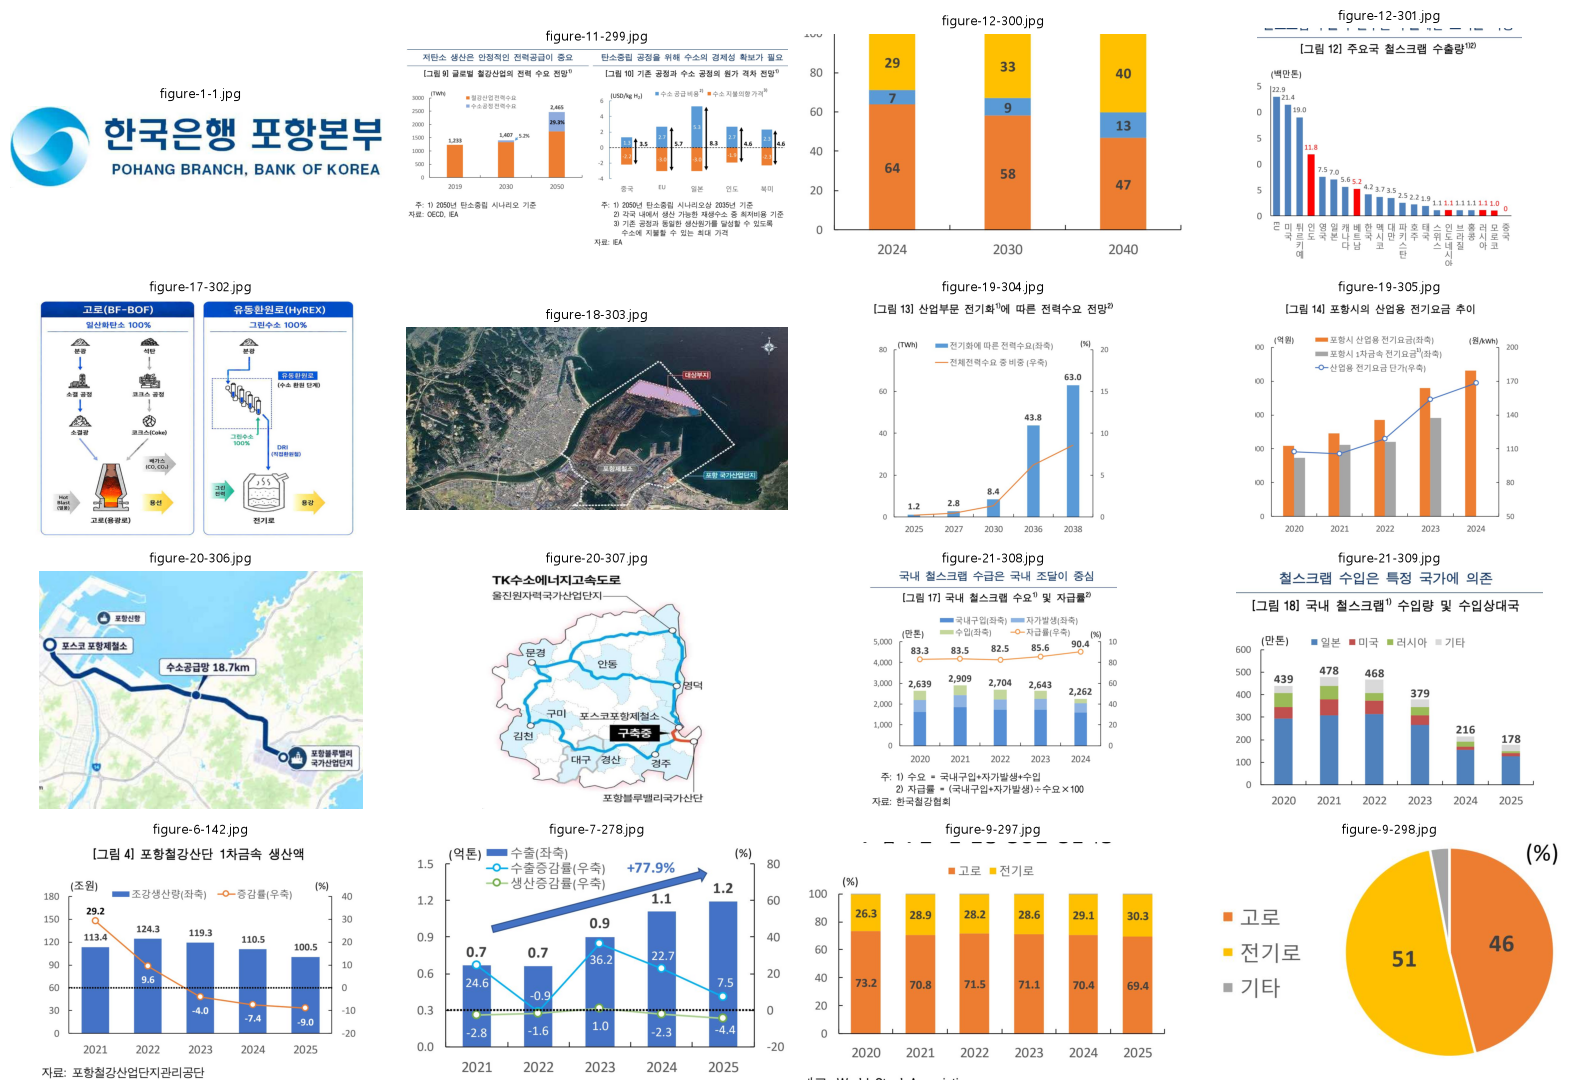

In [5]:
# 체크포인트 1: figures/ 폴더에 추출된 그림 확인
import matplotlib.pyplot as plt
from PIL import Image
plt.rcParams["font.family"] = "Malgun Gothic"

figs = sorted(FIGURES_DIR.glob("*.jpg"))
print(f"figures/ 이미지 {len(figs)}장:", [f.name for f in figs])

big = [f for f in figs if f.stat().st_size >= 8 * 1024]
print(f"8KB 이상(요약 대상) {len(big)}장 / 나머지는 표 안의 아이콘·기호 조각")
fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, big[:16]):
    ax.imshow(Image.open(f)); ax.set_title(f.name, fontsize=9); ax.axis("off")
for ax in axes.flat[len(big[:16]):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. 텍스트 · 표 요약 (②)
LCEL 체인: `{"element": lambda x: x} | prompt | model | StrOutputParser()`
요약 결과는 `data/cache/`에 저장되어 재실행 시 API를 다시 호출하지 않습니다.

In [6]:
from src.summarize import generate_text_summaries

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)
print("텍스트 요약 수:", len(text_summaries), "| 표 요약 수:", len(table_summaries))
print("\n[text_summaries[1]]\n", text_summaries[1])
print("\n[table_summaries[3]]\n", table_summaries[3])

텍스트 요약 수: 33 | 표 요약 수: 5

[text_summaries[1]]
 글로벌 철강산업은 공급과잉과 중국의 수출 확대에 따른 경쟁압력이 증가하고 있으며, 주요국은 반덤핑, 관세, 수입 쿼터, 세이프가드 등 다양한 수입규제를 강화하고 있다. 탄소중립 전환은 철강제품의 탄소배출량을 새로운 경쟁조건으로 부각시키고 있으며, EU의 탄소국경조정제도(CBAM) 시행으로 수출기업은 탄소배출량 측정 및 관리 체계를 갖춰야 한다. 이에 따라 저탄소 생산방식으로의 전환이 확대되고, 안정적인 전력 및 수소 공급과 재생철자원 확보가 중요해지고 있다. 2026년 6월 시행된 K-스틸법은 철강산업의 경쟁력 강화와 탄소중립 전환을 지원하는 제도적 기반을 마련하고, 저탄소 철강기술 개발 및 인증, 인력양성 등을 통해 산업 생태계의 전환을 종합적으로 지원할 예정이다.

[table_summaries[3]]
 **요약:**  
- **2024.1**: 포항제철소 내 수소환원제철 개발센터 개소 및 시험 설비 연구 시작  
- **2026.3~4**: 포항국가산업단지 변경 승인 및 연간 30만 톤 규모 실증플랜트 착공  
- **2026.6**: 광양제철소 대형 전기로 상업 가동 (연산 250만 톤)  
- **2028**: 포항 실증플랜트 완공 및 가동 개시 (연산 30만 톤 수소환원제철 실증 조업)  
- **2030**: HyREX 상용화 기술 확보 목표  
- **2040**: 탄소 배출량 50% 감축 달성  
- **2050**: 포항·광양제철소 모든 고로를 HyREX 설비로 100% 전환 (탄소중립 달성)


## 4. 이미지 요약 (②, VLM)
이미지는 그 자체로 임베딩·검색되지 않으므로 **VLM으로 텍스트 요약**을 만들어 검색에 사용합니다.
8KB 미만 이미지(아이콘·장식선)는 검색 노이즈라 제외합니다.
잘린 그래프에는 제목이 빠져 있으므로, **같은 페이지의 `[그림 N] 제목` 목록**을 VLM에 힌트로 함께 전달합니다.

In [7]:
from src.summarize import encode_image, generate_img_summaries

print("Base64 인코딩 앞 100자:", encode_image(big[0])[:100])

captions = figure_captions(PDF_PATH)
print("페이지별 그림 제목 예시:", captions.get(6))

img_base64_list, image_summaries, img_files = generate_img_summaries(str(FIGURES_DIR), min_kb=8, captions=captions)
print(f"\n요약한 이미지 수: {len(image_summaries)}\n")
for f, s in zip(img_files, image_summaries):
    print(f"■ {f}\n{s}\n")

Base64 인코딩 앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


페이지별 그림 제목 예시: ['[그림3] 포항지역 제조업 및 1차금속 제조업 비중', '[그림4] 포항철강산단 1차금속 생산액']

요약한 이미지 수: 16

■ figure-1-1.jpg
주제: 한국은행 포항본부 로고 이미지  
이 이미지는 한국은행 포항본부의 공식 로고로, 은행의 상징적인 원형 로고와 한글 및 영문 명칭이 포함된 장식용 이미지입니다.  
검색 키워드: 한국은행, 포항본부, 로고, 은행로고, 기관로고

■ figure-11-299.jpg
주제: 글로벌 철강산업의 전력 수요 및 수소 공정 원가 격차 전망

[그림 9]는 글로벌 철강산업의 전력 수요 전망을 나타낸 막대그래프로, x축은 연도(2019, 2030, 2050), y축은 전력수요(TWh)를 표시합니다. 주황색은 '철강산업 전력수요', 파란색은 '수소공정 전력수요'를 의미합니다. 2019년 철강산업 전력수요는 1,233TWh, 2030년 1,407TWh(수소공정 5.2% 포함), 2050년 2,465TWh(수소공정 29.3% 포함)로, 시간이 지날수록 전체 전력수요와 수소공정 비중이 크게 증가하는 추세입니다.

[그림 10]은 기존 공정과 수소 공정의 원가 격차 전망을 보여주는 막대그래프로, x축은 국가(중국, EU, 일본, 인도, 북미), y축은 USD/kg H₂ 단위의 원가 격차입니다. 파란색은 '수소 공급 비용', 주황색은 '수소 지불의향 가격'을 나타냅니다. 예를 들어, 일본의 경우 수소 공급 비용은 5.3, 수소 지불의향 가격은 -3.0으로 격차가 8.3입니다. 전반적으로 모든 지역에서 수소 공급 비용이 수소 지불의향 가격보다 높아, 수소 공정의 경제성 확보가 필요함을 시사합니다.

검색 키워드: 철강산업 전력수요, 수소공정, 원가 격차, 탄소중립, 국가별 비교, 에너지 전망

■ figure-12-300.jpg
주제: 글로벌 철강 생산용 금속 원료 구성의 연도별 변화 전망

차트 유형은 세로 누적 막대그래프이며, [그림11] 글로벌 철강 생산용 금속 원료 구성 전망을 보여준다.

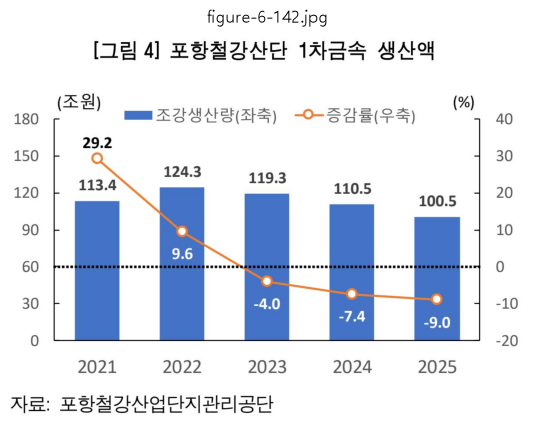

주제: 포항철강산단 1차금속 생산액 및 증감률 추이

차트 유형은 막대와 꺾은선 혼합 그래프이며, 제목은 "[그림 4] 포항철강산단 1차금속 생산액"입니다. X축은 연도(2021~2025), Y축 왼쪽은 생산액(조원), 오른쪽은 증감률(%)입니다. 파란색 막대는 '조강생산량(좌측)'을, 주황색 선은 '증감률(우측)'을 나타냅니다. 주요 수치는 2021년 113.4조원(29.2%), 2022년 124.3조원(9.6%), 2023년 119.3조원(-4.0%), 2024년 110.5조원(-7.4%), 2025년 100.5조원(-9.0%)입니다. 전체적으로 생산액은 2022년 정점 이후 감소세이며, 증감률도 2023년부터 음수로 전환되어 하락 추세가 뚜렷합니다.

검색 키워드: 포항철강산단, 1차금속, 생산액, 증감률, 연도별 변화, 산업통계 



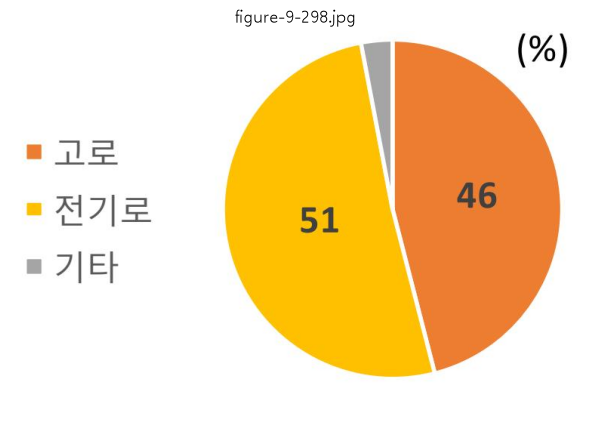

주제: 2026~2028년 글로벌 신규 철강 생산설비 구성 비율

원형 차트로 2026~2028년 글로벌 신규 생산설비의 구성 비율을 나타냄. 범례는 고로(주황색), 전기로(노란색), 기타(회색)로 구성되어 있음. 전기로가 51%로 가장 높은 비중을 차지하고, 고로는 46%, 기타는 소수임. 전체적으로 전기로 설비 비중이 고로보다 높음.

검색 키워드: 글로벌 철강, 신규 생산설비, 고로, 전기로, 생산비중 



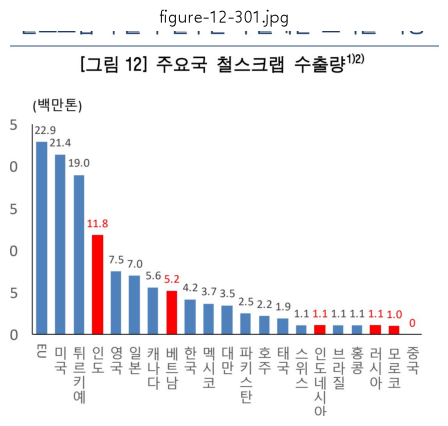

주제: 주요국 철스크랩 수출량 비교

막대그래프이며, 제목은 "[그림 12] 주요국 철스크랩 수출량"입니다. y축은 "백만톤" 단위로 철스크랩 수출량을 나타내고, x축에는 여러 국가명이 나열되어 있습니다. 파란색 막대는 미국(22.9), 독일(21.4), 영국(19.0), 일본(7.5), 네덜란드(7.0), 멕시코(5.6), 대만(4.2), 코스타리카(3.7), 파키스탄(3.5), 호주(2.5), 태국(2.2), 스페인(1.9), 인도네시아(1.1) 등이며, 빨간색 막대는 이탈리아(11.8), 벨기에(5.2), 인도(1.1), 브라질(1.1), 홍콩(1.1), 러시아(1.1), 모로코(1.0), 중국(0)입니다. 전체적으로 미국, 독일, 영국이 가장 높은 수출량을 보이고, 그 외 국가는 상대적으로 낮은 수치를 기록합니다.

검색 키워드: 철스크랩, 수출량, 국가별, 철강, 무역, 주요국 



In [8]:
# 체크포인트 3: 요약문이 실제 그림과 일치하는지 육안 검증
# figure-12-301은 VLM이 세로쓰기 국가명을 잘못 읽은 실패 사례 (README 6장)
for name in ["figure-6-142.jpg", "figure-9-298.jpg", "figure-12-301.jpg"]:
    i = img_files.index(name)
    plt.figure(figsize=(12, 5)); plt.imshow(Image.open(FIGURES_DIR / name)); plt.axis("off"); plt.title(name); plt.show()
    print(image_summaries[i], "\n")

## 5. 다중 벡터 검색기 (Multi-Vector Retriever)
- **벡터DB(Chroma)**: 요약 임베딩 = 색인 카드 서랍
- **docstore(InMemoryStore)**: 원본(텍스트·표 문자열, 이미지 Base64) = 서가
- 둘을 **같은 `doc_id`**로 연결 → 요약으로 찾으면 원본이 나옴

In [9]:
from src.retriever import create_multi_vector_retriever, add_documents, matched_types

retriever = create_multi_vector_retriever(k=4)
add_documents(retriever, text_summaries, texts_2k_token, "text")
add_documents(retriever, table_summaries, tables, "table")
add_documents(retriever, image_summaries, img_base64_list, "image")
print("벡터DB 요약 수:", retriever.vectorstore._collection.count())
print("docstore 원본 수:", len(list(retriever.docstore.yield_keys())))

벡터DB 요약 수: 54
docstore 원본 수: 54


In [10]:
from src.chain import split_image_text_types

q = "포항철강산단 1차금속 생산액 추이"
docs = retriever.invoke(q)
sp = split_image_text_types(docs)
print("매칭된 요약 종류:", matched_types(retriever, q))
print(f"반환된 원본 → 이미지 {len(sp['images'])}개, 텍스트/표 {len(sp['texts'])}개")
print("이미지 원본 앞 60자:", sp["images"][0][:60] if sp["images"] else "-")

매칭된 요약 종류: ['image', 'text', 'image', 'text']
반환된 원본 → 이미지 2개, 텍스트/표 2개
이미지 원본 앞 60자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsL


## 6. Final Answer Pipeline (③)
`retriever → split_image_text_types → img_prompt_func(이미지 먼저 + 텍스트 + 질문) → gpt-4.1 → StrOutputParser`

In [11]:
from src.chain import build_multimodal_chain

chain = build_multimodal_chain(retriever, lang="ko")

QUESTIONS = [
    "국내 철스크랩 수입량은 2020년부터 2025년까지 어떻게 변했고, 주로 어느 나라에서 수입했어?",
    "포항철강산단 1차금속 생산액은 2021년부터 2025년까지 어떻게 변했어?",
    "2026~2028년 글로벌 신규 생산설비 구성 비중은?",
    "포항 수소환원제철 실증플랜트는 언제 완공되고 규모는 얼마야?",
    "글로벌 철강 생산용 금속 원료 구성은 2024년, 2030년, 2040년에 각각 어떻게 전망돼?",
]

results = []
for q in QUESTIONS:
    ans = chain.invoke(q)
    types = matched_types(retriever, q)
    results.append({"question": q, "multimodal": ans, "sources": types})
    print(f"Q. {q}\n근거 원본 종류: {types}\nA. {ans}\n" + "-" * 80)

Q. 국내 철스크랩 수입량은 2020년부터 2025년까지 어떻게 변했고, 주로 어느 나라에서 수입했어?
근거 원본 종류: ['image', 'text', 'text', 'image']
A. 국내 철스크랩 수입량은 2020년 439만 톤, 2021년 478만 톤, 2022년 468만 톤, 2023년 379만 톤, 2024년 216만 톤, 2025년 178만 톤으로 나타났습니다.  
수입량은 2021년에 가장 많았고, 이후 지속적으로 감소하는 추세입니다.

주요 수입국은 일본이 가장 큰 비중을 차지하고 있으며, 그 외에 미국, 러시아, 기타 국가에서 수입하고 있습니다.  
그래프에서 일본(파란색)이 전체 수입량의 대부분을 차지하고 있음을 확인할 수 있습니다.
--------------------------------------------------------------------------------


Q. 포항철강산단 1차금속 생산액은 2021년부터 2025년까지 어떻게 변했어?
근거 원본 종류: ['image', 'text', 'text', 'text']
A. 포항철강산단 1차금속 생산액은 2021년부터 2025년까지 다음과 같이 변했습니다.

- 2021년: 113.4조원
- 2022년: 124.3조원
- 2023년: 119.3조원
- 2024년: 110.5조원
- 2025년: 100.5조원

즉, 2021년에서 2022년까지는 증가(113.4조원 → 124.3조원, 증감률 9.6%)했으나, 2023년부터 2025년까지는 3년 연속 감소(119.3조원 → 110.5조원 → 100.5조원, 증감률 각각 -4.0%, -7.4%, -9.0%)했습니다.
--------------------------------------------------------------------------------


Q. 2026~2028년 글로벌 신규 생산설비 구성 비중은?
근거 원본 종류: ['image', 'text', 'image', 'text']
A. 2026~2028년 글로벌 신규 생산설비 구성 비중은 다음과 같습니다.

- 고로: 46%
- 전기로: 51%
- 기타: 3%

위 수치는 [그림 8]의 원형 그래프에서 확인할 수 있습니다.
--------------------------------------------------------------------------------


Q. 포항 수소환원제철 실증플랜트는 언제 완공되고 규모는 얼마야?
근거 원본 종류: ['table', 'text', 'text', 'text']
A. 포항 수소환원제철 실증플랜트는 2028년에 완공 및 가동을 시작하며, 연간 30만 톤 규모이다.
--------------------------------------------------------------------------------


Q. 글로벌 철강 생산용 금속 원료 구성은 2024년, 2030년, 2040년에 각각 어떻게 전망돼?
근거 원본 종류: ['text', 'image', 'text', 'text']
A. 글로벌 철강 생산용 금속 원료 구성은 다음과 같습니다.

- 2024년: 고로용 철광석 64%, DRI용 철광석 7%, 철스크랩 29%
- 2030년: 고로용 철광석 58%, DRI용 철광석 9%, 철스크랩 33%
- 2040년: 고로용 철광석 47%, DRI용 철광석 13%, 철스크랩 40%
--------------------------------------------------------------------------------


## 7. Before / After — 텍스트 전용 RAG vs 멀티모달 RAG
같은 질문·같은 답변 모델(gpt-4.1)·같은 지시문으로, 검색 대상만 **텍스트 원문 청크**로 제한한 일반 RAG와 비교합니다.

In [12]:
from src.retriever import create_text_only_retriever
from src.chain import build_text_only_chain

text_only_chain = build_text_only_chain(create_text_only_retriever(texts_2k_token, k=4))
for r in results:
    r["text_only"] = text_only_chain.invoke(r["question"])
    print(f"Q. {r['question']}\n[텍스트 RAG]\n{r['text_only']}\n[멀티모달 RAG]\n{r['multimodal']}\n" + "=" * 80)

Q. 국내 철스크랩 수입량은 2020년부터 2025년까지 어떻게 변했고, 주로 어느 나라에서 수입했어?
[텍스트 RAG]
2020년부터 2025년까지 국내 철스크랩 수입량은 다음과 같이 변했습니다.

- 2020년: 439만 톤
- 2021년: 478만 톤
- 2022년: 468만 톤
- 2023년: 379만 톤
- 2024년: 216만 톤
- 2025년: 178만 톤

주로 일본과 미국 등 특정 국가에서 수입했습니다.
[멀티모달 RAG]
국내 철스크랩 수입량은 2020년 439만 톤, 2021년 478만 톤, 2022년 468만 톤, 2023년 379만 톤, 2024년 216만 톤, 2025년 178만 톤으로 나타났습니다.  
수입량은 2021년에 가장 많았고, 이후 지속적으로 감소하는 추세입니다.

주요 수입국은 일본이 가장 큰 비중을 차지하고 있으며, 그 외에 미국, 러시아, 기타 국가에서 수입하고 있습니다.  
그래프에서 일본(파란색)이 전체 수입량의 대부분을 차지하고 있음을 확인할 수 있습니다.


Q. 포항철강산단 1차금속 생산액은 2021년부터 2025년까지 어떻게 변했어?
[텍스트 RAG]
포항철강산단 1차금속 생산액은 2021년 124.3조원, 2022년 119.3조원, 2023년 110.5조원, 2024년 100.5조원, 2025년 91.5조원으로 나타났다. 2021년부터 2025년까지 매년 감소하였다.
[멀티모달 RAG]
포항철강산단 1차금속 생산액은 2021년부터 2025년까지 다음과 같이 변했습니다.

- 2021년: 113.4조원
- 2022년: 124.3조원
- 2023년: 119.3조원
- 2024년: 110.5조원
- 2025년: 100.5조원

즉, 2021년에서 2022년까지는 증가(113.4조원 → 124.3조원, 증감률 9.6%)했으나, 2023년부터 2025년까지는 3년 연속 감소(119.3조원 → 110.5조원 → 100.5조원, 증감률 각각 -4.0%, -7.4%, -9.0%)했습니다.


Q. 2026~2028년 글로벌 신규 생산설비 구성 비중은?
[텍스트 RAG]
2026~2028년 글로벌 신규 생산설비 구성 비중에 대한 자료는 주어지지 않았습니다. 자료에 해당 수치나 비중이 명시되어 있지 않습니다.
[멀티모달 RAG]
2026~2028년 글로벌 신규 생산설비 구성 비중은 다음과 같습니다.

- 고로: 46%
- 전기로: 51%
- 기타: 3%

위 수치는 [그림 8]의 원형 그래프에서 확인할 수 있습니다.


Q. 포항 수소환원제철 실증플랜트는 언제 완공되고 규모는 얼마야?
[텍스트 RAG]
포항 수소환원제철 실증플랜트는 현재 구축이 진행 중이다. 완공 시점과 규모에 대해서는 자료에 명시되어 있지 않다.
[멀티모달 RAG]
포항 수소환원제철 실증플랜트는 2028년에 완공 및 가동을 시작하며, 연간 30만 톤 규모이다.


Q. 글로벌 철강 생산용 금속 원료 구성은 2024년, 2030년, 2040년에 각각 어떻게 전망돼?
[텍스트 RAG]
글로벌 철강 생산용 금속 원료 구성은 다음과 같습니다.

- 2024년:  
  - 고로용 철광석 64%
  - DRI용 철광석 7%
  - 철스크랩 29%

- 2030년:  
  - 고로용 철광석 58%
  - DRI용 철광석 9%
  - 철스크랩 33%

- 2040년:  
  - 고로용 철광석 47%
  - DRI용 철광석 13%
  - 철스크랩 40%
[멀티모달 RAG]
글로벌 철강 생산용 금속 원료 구성은 다음과 같습니다.

- 2024년: 고로용 철광석 64%, DRI용 철광석 7%, 철스크랩 29%
- 2030년: 고로용 철광석 58%, DRI용 철광석 9%, 철스크랩 33%
- 2040년: 고로용 철광석 47%, DRI용 철광석 13%, 철스크랩 40%


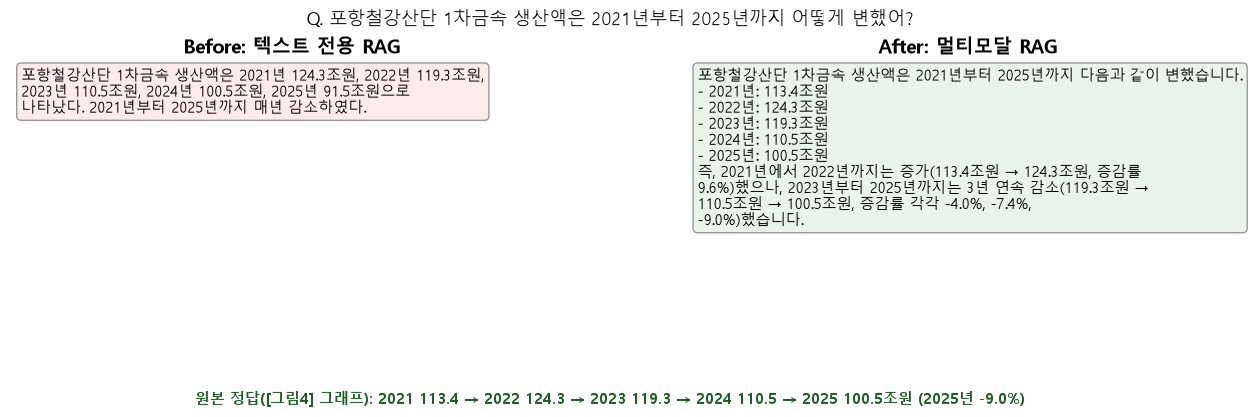

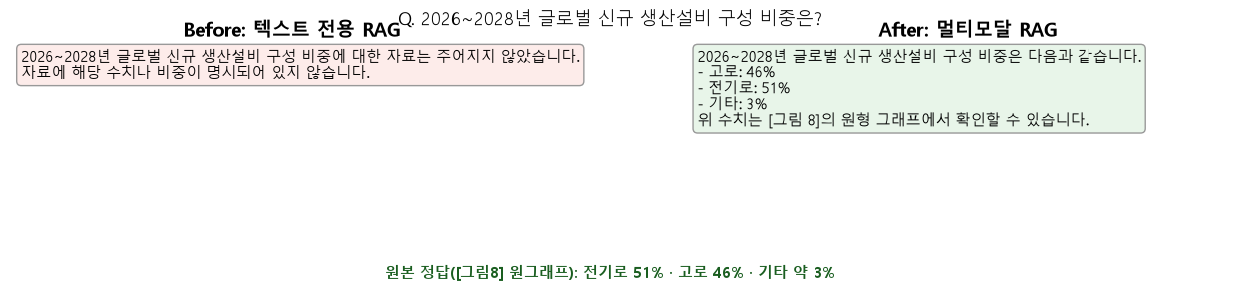

In [13]:
# 결과 저장 (README 작성용) + 비교 캡처 이미지 생성
import json, textwrap
DOCS = ROOT / "docs"; DOCS.mkdir(exist_ok=True)
(DOCS / "qa_results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")

def wrap(s, w=48):
    s = s.replace("**", "")
    return chr(10).join(textwrap.fill(line, w) for line in s.splitlines() if line.strip())

TRUTH = {
    1: "원본 정답([그림4] 그래프): 2021 113.4 → 2022 124.3 → 2023 119.3 → 2024 110.5 → 2025 100.5조원 (2025년 -9.0%)",
    2: "원본 정답([그림8] 원그래프): 전기로 51% · 고로 46% · 기타 약 3%",
}
for idx in [1, 2]:
    r = results[idx]
    left, right = wrap(r["text_only"]), wrap(r["multimodal"])
    h = 1.6 + 0.24 * max(left.count(chr(10)), right.count(chr(10)))
    fig, axes = plt.subplots(1, 2, figsize=(16, h))
    for ax, txt, title, color in [(axes[0], left, "Before: 텍스트 전용 RAG", "#fdecea"),
                                  (axes[1], right, "After: 멀티모달 RAG", "#e8f5e9")]:
        ax.axis("off"); ax.set_title(title, fontsize=14, fontweight="bold")
        ax.text(0.02, 0.98, txt, va="top", fontsize=11, transform=ax.transAxes,
                bbox=dict(boxstyle="round", facecolor=color, edgecolor="#999"))
    fig.suptitle("Q. " + r["question"], fontsize=13, y=1.02)
    fig.text(0.5, -0.03, TRUTH[idx], ha="center", fontsize=11, color="#1a5e20", fontweight="bold")
    fig.savefig(DOCS / f"before_after_q{idx+1}.png", dpi=110, bbox_inches="tight"); plt.show()

### 정답 검증 (원본 그래프·표를 직접 보고 확인)
| 질문 | 원본 정답 | 근거 |
|---|---|---|
| Q1 철스크랩 수입 | 439 → 478 → 468 → 379 → 216 → 178만톤, 일본 비중 최대 | [그림18] (이미지, 국가별 값은 색으로만 표시) |
| Q2 1차금속 생산액 | 113.4 → 124.3 → 119.3 → 110.5 → 100.5조원 | [그림4] (이미지) |
| Q3 신규 생산설비 | 전기로 51% · 고로 46% · 기타 | [그림8] 원그래프 (이미지) |
| Q4 실증플랜트 | 2028년 완공, 연산 30만 톤 | 수소환원제철 추진 일정 표 (Table) |
| Q5 금속 원료 구성 | 고로용 철광석 64→58→47 / DRI용 7→9→13 / 철스크랩 29→33→40 | [그림11] (이미지 + 텍스트 레이어 범례) |

**텍스트 RAG가 틀리는 이유:** 텍스트 레이어에는 그래프 라벨이 `113.4 124.3 119.3 110.5 100.5 29.2 9.6 -4.0 ...`처럼 **연도 없이 숫자만** 나열됩니다.
모델이 연도를 한 칸씩 밀어 매칭하거나 없는 값을 지어내며(Q2), 원그래프·일정표처럼 본문에 서술되지 않은 정보는 아예 찾지 못합니다(Q3, Q4).

### 부록: 추가 실험 (성공 · 실패 사례 포함)
선정한 5건 외에 4개 질문을 더 시험했습니다. **멀티모달 RAG가 틀리는 사례**도 포함되어 있습니다(README 6장).

In [14]:
EXTRA = [
    "중국의 철강 수출량은 2021년부터 2025년까지 어떻게 변했어?",
    "포항시 산업용 전기요금 단가는 2020년부터 2024년까지 어떻게 변했어?",
    "산업부문 전기화에 따른 전력수요는 연도별로 어떻게 전망돼?",
    "주요국 철스크랩 수출량 상위 3개국과 수출량은?",
]
extra_results = []
for q in EXTRA:
    r = {"question": q, "multimodal": chain.invoke(q), "text_only": text_only_chain.invoke(q), "sources": matched_types(retriever, q)}
    extra_results.append(r)
    print(f"Q. {q}", f"근거 원본 종류: {r['sources']}", "[텍스트 RAG]", r["text_only"], "[멀티모달 RAG]", r["multimodal"], "=" * 80, sep=chr(10))
(DOCS / "extra_results.json").write_text(json.dumps(extra_results, ensure_ascii=False, indent=2), encoding="utf-8")

Q. 중국의 철강 수출량은 2021년부터 2025년까지 어떻게 변했어?
근거 원본 종류: ['text', 'table', 'image', 'text']
[텍스트 RAG]
중국의 철강 수출량은 2021년 0.7억 톤, 2022년 0.9억 톤, 2023년 0.9억 톤, 2024년 1.1억 톤, 2025년 1.2억 톤으로 증가했다. 2021년부터 2025년까지 중국의 철강 수출량은 0.7억 톤에서 1.2억 톤으로 77.9% 증가했다.
[멀티모달 RAG]
중국의 철강 수출량은 2021년 0.7억 톤, 2022년 0.7억 톤, 2023년 0.9억 톤, 2024년 1.1억 톤, 2025년 1.2억 톤으로 증가했습니다. 2021년부터 2025년까지 수출량은 0.7억 톤에서 1.2억 톤으로 77.9% 증가했습니다.


Q. 포항시 산업용 전기요금 단가는 2020년부터 2024년까지 어떻게 변했어?
근거 원본 종류: ['image', 'text', 'text', 'text']
[텍스트 RAG]
포항시 산업용 전기요금 단가는 2020년부터 2024년까지 다음과 같이 변했습니다.

- 2020년: 약 80원/kWh
- 2021년: 약 110원/kWh
- 2022년: 약 140원/kWh
- 2023년: 약 170원/kWh
- 2024년: 약 200원/kWh

따라서 2020년부터 2024년까지 포항시 산업용 전기요금 단가는 꾸준히 상승했습니다.
[멀티모달 RAG]
포항시 산업용 전기요금 단가는 2020년부터 2024년까지 다음과 같이 변했습니다.

- 2020년: 약 110원/kWh
- 2021년: 약 105원/kWh
- 2022년: 약 120원/kWh
- 2023년: 약 150원/kWh
- 2024년: 약 170원/kWh

즉, 2020년에는 약 110원/kWh 수준이었으나 2021년에 소폭 하락했다가, 2022년부터 꾸준히 상승하여 2024년에는 약 170원/kWh로 크게 증가했습니다.


Q. 산업부문 전기화에 따른 전력수요는 연도별로 어떻게 전망돼?
근거 원본 종류: ['image', 'image', 'text', 'text']
[텍스트 RAG]
산업부문의 전기화에 따른 연도별 전력수요 전망은 다음과 같습니다.

- 2025년: 1.2TWh
- 2027년: 2.8TWh
- 2030년: 8.4TWh
- 2036년: 43.8TWh
- 2038년: 63.0TWh

이 수치는 [그림 13] 산업부문 전기화에 따른 전력수요 전망에서 확인할 수 있습니다.
[멀티모달 RAG]
산업부문 전기화에 따른 전력수요는 연도별로 다음과 같이 전망돼:

- 2025년: 1.2TWh
- 2027년: 2.8TWh
- 2030년: 8.4TWh
- 2036년: 43.8TWh
- 2038년: 63.0TWh

이 수치는 [그림 13]의 막대그래프에서 확인할 수 있어.


Q. 주요국 철스크랩 수출량 상위 3개국과 수출량은?
근거 원본 종류: ['image', 'image', 'image', 'text']
[텍스트 RAG]
주요국 철스크랩 수출량 상위 3개국과 수출량은 다음과 같습니다.

1. EU: 2,290만 톤 (22.9백만 톤)
2. 미국: 2,140만 톤 (21.4백만 톤)
3. 튀르키예: 1,900만 톤 (19.0백만 톤)

(출처: [그림 12] 주요국 철스크랩 수출량, 2025년 기준)
[멀티모달 RAG]
주요국 철스크랩 수출량 상위 3개국과 수출량은 다음과 같습니다.  
- 미국: 2,290만 톤  
- 터키: 2,140만 톤  
- 네덜란드: 1,900만 톤  
(출처: [그림 12] 주요국 철스크랩 수출량)


2109

## 8. 번역 체인 통합 (선택)
영어로 답변을 생성한 뒤 번역 모델로 한국어로 옮깁니다.
로컬 Ollama(`llama3.1:8b`)가 실행 중이면 오픈소스 모델을, 없으면 `gpt-4o-mini`를 사용합니다.

In [15]:
from src.chain import get_translator, build_translate_chain

english_chain = build_multimodal_chain(retriever, lang="en")
translator, translator_name = get_translator()
final_chain = build_translate_chain(english_chain, translator)

q = QUESTIONS[1]
print("번역 모델:", translator_name)
print("\n[영문 답변]\n", english_chain.invoke(q))
print("\n[한국어 번역]\n", final_chain.invoke(q))

번역 모델: openai:gpt-4o-mini



[영문 답변]
 From 2021 to 2025, the primary metal production amount at the Pohang Steel Industrial Complex changed as follows (unit: trillion KRW):

- 2021: 113.4
- 2022: 124.3
- 2023: 119.3
- 2024: 110.5
- 2025: 100.5

The production amount increased from 113.4 in 2021 to 124.3 in 2022, then decreased each year to 100.5 in 2025.



[한국어 번역]
 2021년부터 2025년까지 포항제철 산업단지의 주요 금속 생산량은 다음과 같이 변화했습니다 (단위: 조 원):

- 2021: 113.4
- 2022: 124.3
- 2023: 119.3
- 2024: 110.5
- 2025: 100.5

생산량은 2021년 113.4에서 2022년 124.3으로 증가한 후, 매년 감소하여 2023년 119.3, 2024년 110.5, 2025년 100.5에 이르렀습니다.


## 정리
- **검색에는 요약, 답변에는 원본**: 그래프는 요약(텍스트)으로 바꿔야 검색되지만, 요약은 수치를 잘못 옮기거나 빠뜨릴 수 있으므로 답변 단계에서는 원본 이미지를 직접 보게 한다.
- 텍스트 전용 RAG는 본문에 서술되지 않은 **그래프 속 연도별 수치·원그래프·일정표**를 답하지 못하거나 추측하는 반면, 멀티모달 RAG는 원본을 근거로 답한다.
- 단, 세로쓰기 한글 라벨처럼 VLM이 읽기 어려운 그래프는 오히려 텍스트 레이어가 정확할 수 있다(부록 실험).